# Pretrained SOTA Edge Models - MobileNetV2 on EuroSAT

This notebook performs the transfer learning, fine-tuning, and performance evaluation of **MobileNetV2** on the EuroSAT dataset restricted to **$64 \times 64 \times 3$** resolution. This is designed as a standalone, reproducible SOTA component of our Resource-Constrained CNNs for Edge Image Classification assignment.

## 1. Introduction & MobileNetV2 Architecture Overview

### What is MobileNetV2?
**MobileNetV2** is a state-of-the-art, highly efficient convolutional neural network architecture specifically tailored for mobile and resource-constrained edge devices. Introduced by Google, it improves significantly upon MobileNetV1 by introducing novel block design principles.

### Why is MobileNetV2 suitable for Edge Devices?
Standard deep CNNs (such as VGG or ResNet) require billions of Multiply-Accumulate (MAC) operations and hundreds of megabytes of memory, rendering them impractical for microcontroller or mobile environments. MobileNetV2 reduces both parameters and computational latency dramatically while maintaining high accuracy.

### Key Structural Concepts:
1. **Depthwise Separable Convolution**:
   Instead of a standard convolution that filters and combines inputs in one step, depthwise separable convolution splits this into two steps:
   * **Depthwise Convolution**: Applies a single channel-wise spatial filter to each input channel separately.
   * **Pointwise Convolution ($1 \times 1$)**: Linearly combines the outputs of the depthwise convolution across channels.
   This reduces computation by roughly a factor of $N$ (where $N$ is the number of output channels).

2. **Inverted Residual Blocks**:
   In classic ResNets, residual connections link high-dimensional layers. MobileNetV2 does the inverse: it uses a **narrow-wide-narrow** structure. It expands the low-dimensional input to a higher dimension using a pointwise convolution, performs a spatial depthwise convolution, and then projects it back to a low-dimensional bottleneck using another pointwise convolution. Residual connections are added directly between the low-dimensional bottlenecks.

3. **Linear Bottlenecks**:
   Applying non-linearities (like ReLU) in low-dimensional spaces can inadvertently destroy useful feature information. MobileNetV2 addresses this by removing the non-linear activation (keeping it linear) at the end of each bottleneck layer when projecting back to low-dimensional space.

### Pretrained ImageNet Weights & Transfer Learning
* **ImageNet Pretraining**: Using a model initialized with weights learned from 1.4 million images (ImageNet) transfers high-level feature extraction capabilities (edges, shapes, textures) directly to new domains.
* **Transfer Learning on EuroSAT**: The EuroSAT dataset consists of satellite images. Although satellite imagery looks different from typical ImageNet images, the early-stage visual representations are highly transferrable, allowing us to train a high-performance classifier with extremely low training costs and data requirements.

## 2. Imports and Environment Setup

In [1]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import models, transforms
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support
import pandas as pd
import seaborn as sns

print(f"PyTorch version: {torch.__version__}")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device selected: {device}")

PyTorch version: 2.14.1+cu126
Device selected: cuda


## 3. Reproducibility Configuration
Setting up global random seeds

In [2]:
RANDOM_SEED = 42
os.environ['PYTHONHASHSEED'] = str(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(RANDOM_SEED)
    torch.cuda.manual_seed_all(RANDOM_SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

print(f"Random seed set deterministically to: {RANDOM_SEED}")

Random seed set deterministically to: 42


## 4. Dataset Loading
Load the shared `eurosat_splits.csv` and `eurosat_classes.json` files used by the other model notebooks. The manifest preserves the repository's deterministic train, validation, and test assignments.

In [3]:
from pathlib import Path
from types import SimpleNamespace

import pandas as pd
from torch.utils.data import DataLoader
from PIL import Image
import kagglehub

ROOT = Path.cwd().resolve()
if not (ROOT / "eurosat_data.py").is_file():
    raise FileNotFoundError("Set ROOT to the repository folder containing eurosat_data.py")

import sys
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from eurosat_data import load_splits, validate_images

args = SimpleNamespace(
    data_dir=None,  # Or Path("C:/datasets/EuroSAT")
    splits=ROOT / "eurosat_splits.csv",
    classes=ROOT / "eurosat_classes.json",
    batch_size=32,
    num_workers=0,
)

# Download dataset
if args.data_dir is None:
    dataset_path = kagglehub.dataset_download("apollo2506/eurosat-dataset")
    DATA_DIR = Path(dataset_path) / "EuroSAT"
else:
    DATA_DIR = Path(args.data_dir)

# Load deterministic splits using the project's exact logic
rows, class_names = load_splits(args.splits, args.classes)
manifest = pd.DataFrame(rows)
NUM_CLASSES = len(class_names)
print(manifest["split"].value_counts())
print("Classes:", class_names)

# Validate image paths against downloaded dataset directory
validate_images(rows, DATA_DIR)
print("Dataset directory:", DATA_DIR)
print("All manifest images found.")

class EuroSATDataset:
    def __init__(self, manifest, split, root, transform):
        self.frame = manifest[manifest["split"] == split].reset_index(drop=True)
        self.root = Path(root)
        self.transform = transform
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(self.root / row["relative_path"]) as image:
            image = image.convert("RGB")
            image = self.transform(image)
        return image, int(row["label"])

print("Train size:", len(manifest[manifest["split"] == "train"]))
print("Val size:", len(manifest[manifest["split"] == "val"]))
print("Test size:", len(manifest[manifest["split"] == "test"]))

print("Dataset manifest loaded successfully.")

split
train    18900
val       4050
test      4050
Name: count, dtype: int64
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
Dataset directory: C:\Users\ASUS\.cache\kagglehub\datasets\apollo2506\eurosat-dataset\versions\6\EuroSAT
All manifest images found.
Train size: 18900
Val size: 4050
Test size: 4050
Dataset manifest loaded successfully.


## 5. Dataset Verification
We verify that the image dimensions conform to our critical edge constraint of $64 \times 64 \times 3$.

In [4]:
# Verify a raw image from the manifest-backed dataset.
sample_row = manifest[manifest["split"] == "train"].iloc[0]
with Image.open(DATA_DIR / sample_row["relative_path"]) as sample_image:
    sample_image = sample_image.convert("RGB")
    width, height = sample_image.size

sample_lbl = int(sample_row["label"])
print(f"Sample image size: {width}x{height}")
print(f"Sample label: {sample_lbl} ({class_names[sample_lbl]})")

if width != 64 or height != 64:
    raise ValueError("Images are not 64x64. Adjust dataset pipeline before training.")
print("Dataset verification passed: images are exactly 64x64.")

Sample image size: 64x64
Sample label: 7 (Residential)
Dataset verification passed: images are exactly 64x64.


## 6. Input Preprocessing
The pretrained torchvision MobileNetV2 uses ImageNet channel normalization.

* **Standard Input:** Images are loaded in the range $[0, 255]$ with integer values.
* **Our Pipeline:** Images are resized to $64 \times 64$, converted to tensors in $[0, 1]$, and normalized with the ImageNet mean and standard deviation expected by the pretrained backbone. We construct batched datasets with a batch size of 32.

In [5]:
BATCH_SIZE = args.batch_size
from torchvision import transforms

image_transform = transforms.Compose([
    transforms.Resize(
        (64, 64),
        interpolation=transforms.InterpolationMode.BILINEAR
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset = EuroSATDataset(manifest, "train", DATA_DIR, image_transform)
val_dataset = EuroSATDataset(manifest, "val", DATA_DIR, image_transform)
test_dataset = EuroSATDataset(manifest, "test", DATA_DIR, image_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=args.num_workers, pin_memory=(device.type == "cuda"))
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=args.num_workers, pin_memory=(device.type == "cuda"))
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=args.num_workers, pin_memory=(device.type == "cuda"))

# Verification of batch bounds
images, labels = next(iter(train_loader))
print(f"Preprocessed batch shape: {images.shape}")
print(f"Minimum pixel value in batch: {images.min().item():.4f}")
print(f"Maximum pixel value in batch: {images.max().item():.4f}")

Preprocessed batch shape: torch.Size([32, 3, 64, 64])
Minimum pixel value in batch: -1.7754
Maximum pixel value in batch: 2.6400


## 7. MobileNetV2 Architecture & Functional Model Setup

We instantiate the `MobileNetV2` backbone using the functional API, pre-loaded with `imagenet` weights. Note that the input shape is strictly locked to `(64, 64, 3)` to adhere to the edge image classification constraints.

We strip off the original top classification layers (`include_top=False`), apply global average pooling, add a dropout layer for regularization, and append a custom dense layer for EuroSAT's 10 classes.

In [7]:
import torch
import torch.nn as nn
from torchvision import models

def build_mobilenet_v2_model(num_classes=10):
    # Load pretrained MobileNetV2
    model = models.mobilenet_v2(
        weights=models.MobileNet_V2_Weights.DEFAULT
    )

    # Freeze feature extraction layers
    for param in model.features.parameters():
        param.requires_grad = False

    # Replace classifier for EuroSAT (10 classes)
    in_features = model.classifier[1].in_features

    model.classifier = nn.Sequential(
        nn.Dropout(p=0.3),
        nn.Linear(in_features, num_classes)
    )

    return model


# Build the model
model = build_mobilenet_v2_model(num_classes=10)

# Move model to GPU if CUDA is available
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)

print("Using device:", device)
print(model)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to C:\Users\ASUS/.cache\torch\hub\checkpoints\mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [01:10<00:00, 203kB/s] 


Using device: cuda
MobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1,

## 8. Parameter Analysis

Let us analyze the parameter distribution inside our network structure before beginning Phase 1 training.
* **Total parameters**: Combined weights/biases across the entire architecture.
* **Trainable parameters**: Weights associated with the final classifier that we will update during Stage 1.
* **Non-trainable parameters**: Weights associated with the base feature extractor layers that remain frozen.

In [8]:
def report_parameters(model):
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    non_trainable_params = total_params - trainable_params

    print(f"Total Parameters: {total_params:,}")
    print(f"Trainable Parameters: {trainable_params:,}")
    print(f"Non-Trainable Parameters: {non_trainable_params:,}")
    return total_params, trainable_params, non_trainable_params

total_params, trainable_params, non_trainable_params = report_parameters(model)

Total Parameters: 2,236,682
Trainable Parameters: 12,810
Non-Trainable Parameters: 2,223,872


## 9. Stage 1 — Frozen Backbone Training (Transfer Learning)

In Stage 1, we only train our newly attached classifier head, keeping the base model entirely frozen. This allows us to find good initial weights for the classifier without corrupting the high-quality feature extractors with large initial gradient updates.

In [9]:
INITIAL_EPOCHS = 5
initial_lr = 1e-3

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.classifier.parameters(), lr=initial_lr)

# Tracking history
history_stage1 = {'loss': [], 'val_loss': [], 'accuracy': [], 'val_accuracy': []}

print("Starting Stage 1 training (Frozen Backbone)...")
start_time = time.time()

for epoch in range(INITIAL_EPOCHS):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, targets in train_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total += targets.size(0)
        correct += predicted.eq(targets).sum().item()

    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_acc = correct / total

    # Validation
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0
    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            val_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            val_total += targets.size(0)
            val_correct += predicted.eq(targets).sum().item()

    epoch_val_loss = val_loss / len(val_loader.dataset)
    epoch_val_acc = val_correct / val_total

    history_stage1['loss'].append(epoch_loss)
    history_stage1['accuracy'].append(epoch_acc)
    history_stage1['val_loss'].append(epoch_val_loss)
    history_stage1['val_accuracy'].append(epoch_val_acc)

    print(f"Epoch {epoch+1}/{INITIAL_EPOCHS} - loss: {epoch_loss:.4f} - accuracy: {epoch_acc:.4f} - val_loss: {epoch_val_loss:.4f} - val_accuracy: {epoch_val_acc:.4f}")

stage1_time = time.time() - start_time
print(f"Stage 1 completed in: {stage1_time:.2f} seconds")

Starting Stage 1 training (Frozen Backbone)...
Epoch 1/5 - loss: 0.8855 - accuracy: 0.7430 - val_loss: 0.5793 - val_accuracy: 0.8365
Epoch 2/5 - loss: 0.6447 - accuracy: 0.7980 - val_loss: 0.5190 - val_accuracy: 0.8390
Epoch 3/5 - loss: 0.6160 - accuracy: 0.8070 - val_loss: 0.4780 - val_accuracy: 0.8511
Epoch 4/5 - loss: 0.5978 - accuracy: 0.8123 - val_loss: 0.4711 - val_accuracy: 0.8565
Epoch 5/5 - loss: 0.5896 - accuracy: 0.8125 - val_loss: 0.4881 - val_accuracy: 0.8521
Stage 1 completed in: 126.97 seconds


## 10. Stage 2 — Fine-Tuning

In Stage 2, we unfreeze a custom selection of the top layers of the backbone so they can be carefully adapted to the satellite image domain. We use a significantly reduced learning rate (`1e-5`) to avoid destroying pretrained feature weights.

In [10]:
FINE_TUNE_LAST_N_LAYERS = 30
FINE_TUNE_EPOCHS = 15
fine_tune_lr = 1e-5

# Unfreeze layers selectively
# MobileNetV2 has model.features (sequential layers) and model.classifier
for param in model.parameters():
    param.requires_grad = True

# Since PyTorch's MobileNetV2 feature extractor is highly modular,
# we freeze all layers except the last N parameters.
all_params = list(model.parameters())
freeze_limit = len(all_params) - FINE_TUNE_LAST_N_LAYERS
for i, param in enumerate(all_params):
    if i < freeze_limit:
        param.requires_grad = False

# Re-evaluate parameters
total_params, trainable_params, non_trainable_params = report_parameters(model)

# Setup optimization only for parameters with grad
optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=fine_tune_lr)

history_stage2 = {'loss': [], 'val_loss': [], 'accuracy': [], 'val_accuracy': []}
best_val_loss = float('inf')
checkpoint_path = 'mobilenetv2_best.pth'

print("Starting Stage 2 training (Fine-tuning)...")
start_time = time.time()

for epoch in range(FINE_TUNE_EPOCHS):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, targets in train_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total += targets.size(0)
        correct += predicted.eq(targets).sum().item()

    epoch_loss = running_loss / len(train_loader.dataset)
    epoch_acc = correct / total

    # Validation
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0
    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            val_loss += loss.item() * inputs.size(0)
            _, predicted = outputs.max(1)
            val_total += targets.size(0)
            val_correct += predicted.eq(targets).sum().item()

    epoch_val_loss = val_loss / len(val_loader.dataset)
    epoch_val_acc = val_correct / val_total

    history_stage2['loss'].append(epoch_loss)
    history_stage2['accuracy'].append(epoch_acc)
    history_stage2['val_loss'].append(epoch_val_loss)
    history_stage2['val_accuracy'].append(epoch_val_acc)

    print(f"Epoch {INITIAL_EPOCHS + epoch+1}/{INITIAL_EPOCHS + FINE_TUNE_EPOCHS} - loss: {epoch_loss:.4f} - accuracy: {epoch_acc:.4f} - val_loss: {epoch_val_loss:.4f} - val_accuracy: {epoch_val_acc:.4f}")

    # Save best checkpoint
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict(), checkpoint_path)
        print("==> Checkpoint saved!")

stage2_time = time.time() - start_time
print(f"Stage 2 completed in: {stage2_time:.2f} seconds")

Total Parameters: 2,236,682
Trainable Parameters: 1,384,330
Non-Trainable Parameters: 852,352
Starting Stage 2 training (Fine-tuning)...
Epoch 6/20 - loss: 0.5399 - accuracy: 0.8250 - val_loss: 0.3911 - val_accuracy: 0.8728
==> Checkpoint saved!
Epoch 7/20 - loss: 0.4889 - accuracy: 0.8379 - val_loss: 0.3432 - val_accuracy: 0.8825
==> Checkpoint saved!
Epoch 8/20 - loss: 0.4423 - accuracy: 0.8540 - val_loss: 0.3469 - val_accuracy: 0.8822
Epoch 9/20 - loss: 0.4180 - accuracy: 0.8599 - val_loss: 0.3037 - val_accuracy: 0.8914
==> Checkpoint saved!
Epoch 10/20 - loss: 0.4045 - accuracy: 0.8633 - val_loss: 0.2893 - val_accuracy: 0.9020
==> Checkpoint saved!
Epoch 11/20 - loss: 0.3786 - accuracy: 0.8735 - val_loss: 0.2860 - val_accuracy: 0.9059
==> Checkpoint saved!
Epoch 12/20 - loss: 0.3715 - accuracy: 0.8775 - val_loss: 0.2699 - val_accuracy: 0.9084
==> Checkpoint saved!
Epoch 13/20 - loss: 0.3476 - accuracy: 0.8813 - val_loss: 0.2552 - val_accuracy: 0.9148
==> Checkpoint saved!
Epoch 14/

## 11. Complete Training Curve Analysis
We combine the logs from both Stage 1 and Stage 2 to build our training accuracy and loss curves.

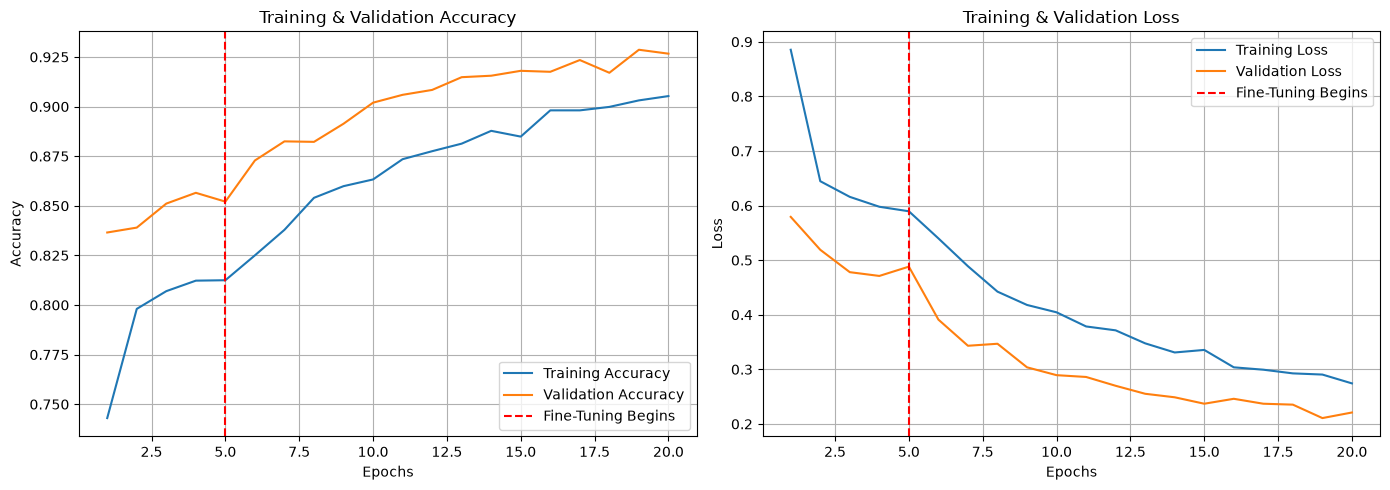

In [11]:
# Combine history records
loss = history_stage1['loss'] + history_stage2['loss']
val_loss = history_stage1['val_loss'] + history_stage2['val_loss']
accuracy = history_stage1['accuracy'] + history_stage2['accuracy']
val_accuracy = history_stage1['val_accuracy'] + history_stage2['val_accuracy']

epochs_range = range(1, len(loss) + 1)

plt.figure(figsize=(14, 5))

# Accuracy Curves
plt.subplot(1, 2, 1)
plt.plot(epochs_range, accuracy, label='Training Accuracy')
plt.plot(epochs_range, val_accuracy, label='Validation Accuracy')
plt.axvline(x=INITIAL_EPOCHS, color='r', linestyle='--', label='Fine-Tuning Begins')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Training & Validation Accuracy')
plt.legend()
plt.grid(True)

# Loss Curves
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.axvline(x=INITIAL_EPOCHS, color='r', linestyle='--', label='Fine-Tuning Begins')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training & Validation Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## 12. Model Evaluation, Size Estimation & Report Export
We load the best saved model, perform evaluation against the test set, plot a confusion matrix, measure actual storage overhead, and build a results table.

Test Set Accuracy: 92.8395%


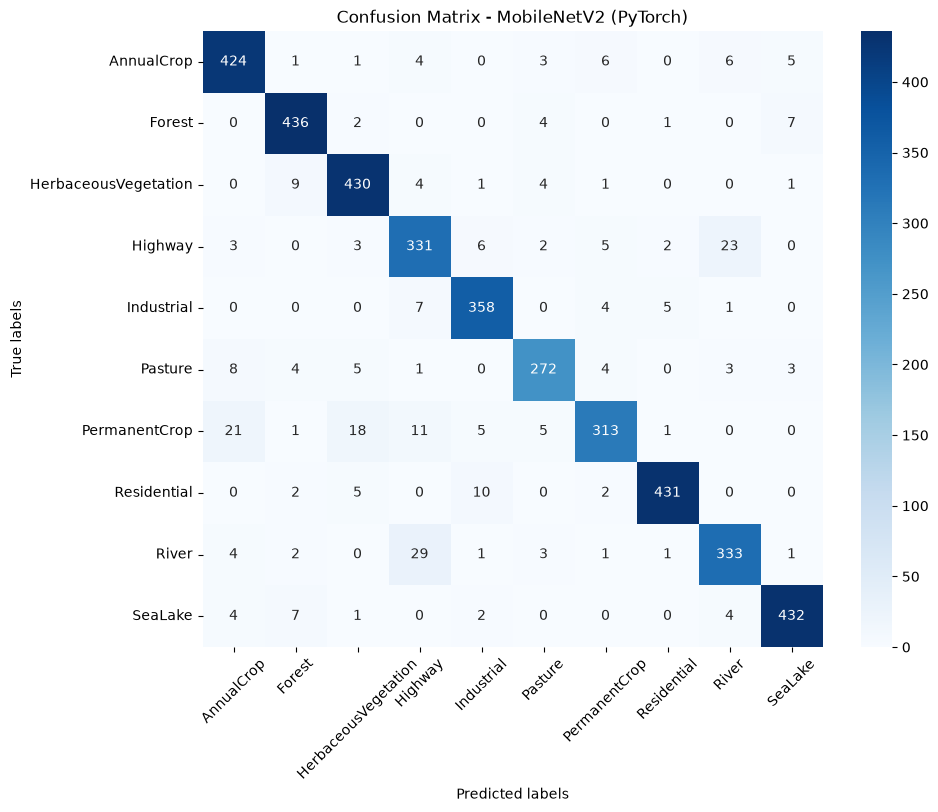

                      precision    recall  f1-score   support

          AnnualCrop       0.91      0.94      0.93       450
              Forest       0.94      0.97      0.96       450
HerbaceousVegetation       0.92      0.96      0.94       450
             Highway       0.86      0.88      0.87       375
          Industrial       0.93      0.95      0.94       375
             Pasture       0.93      0.91      0.92       300
       PermanentCrop       0.93      0.83      0.88       375
         Residential       0.98      0.96      0.97       450
               River       0.90      0.89      0.89       375
             SeaLake       0.96      0.96      0.96       450

            accuracy                           0.93      4050
           macro avg       0.93      0.93      0.93      4050
        weighted avg       0.93      0.93      0.93      4050



,Model,Dataset,Resolution,Total Parameters,Trainable Parameters,Theoretical Model Size (MB),Actual Model Size (MB),Test Accuracy,Macro Precision,Macro Recall,Macro F1-Score,Total Training Time (Min)
0,MobileNetV2 (Pretrained - PyTorch),EuroSAT,64x64x3,2236682,12810,8.532265,8.768321,0.928395,0.927161,0.925111,0.925748,8.846965


In [12]:
# Load best saved model state
best_model = build_mobilenet_v2_model()
best_model.load_state_dict(torch.load('mobilenetv2_best.pth'))
best_model = best_model.to(device)
best_model.eval()

# Evaluate on Test Loader
test_loss = 0.0
test_correct = 0
test_total = 0
y_true = []
y_pred = []

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        outputs = best_model(inputs)
        loss = criterion(outputs, targets)
        test_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        test_total += targets.size(0)
        test_correct += predicted.eq(targets).sum().item()

        y_true.extend(targets.cpu().numpy())
        y_pred.extend(predicted.cpu().numpy())

test_acc = test_correct / test_total
print(f"Test Set Accuracy: {test_acc:.4%}")

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=class_names, yticklabels=class_names, cmap='Blues')
plt.title('Confusion Matrix - MobileNetV2 (PyTorch)')
plt.ylabel('True labels')
plt.xlabel('Predicted labels')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.show()

# Classification Metrics
print(classification_report(y_true, y_pred, target_names=class_names))
precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='macro')

# Calculate size in MB
theoretical_size_mb = (sum(p.numel() for p in best_model.parameters()) * 4) / (1024 * 1024)
saved_model_path = 'mobilenetv2_best.pth'
actual_size_mb = os.path.getsize(saved_model_path) / (1024 * 1024)

# Prepare summary table
results_data = {
    'Model': ['MobileNetV2 (Pretrained - PyTorch)'],
    'Dataset': ['EuroSAT'],
    'Resolution': ['64x64x3'],
    'Total Parameters': [sum(p.numel() for p in best_model.parameters())],
    'Trainable Parameters': [sum(p.numel() for p in best_model.parameters() if p.requires_grad)],
    'Theoretical Model Size (MB)': [theoretical_size_mb],
    'Actual Model Size (MB)': [actual_size_mb],
    'Test Accuracy': [test_acc],
    'Macro Precision': [precision],
    'Macro Recall': [recall],
    'Macro F1-Score': [f1],
    'Total Training Time (Min)': [(stage1_time + stage2_time)/60.0]
}

results_df = pd.DataFrame(results_data)
results_df.to_csv('mobilenetv2_results.csv', index=False)
display(results_df)